In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # parent of the notebook's folder

import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from skimage.transform import AffineTransform, SimilarityTransform
from skimage.measure import ransac
from vol_rec_lm.volume_reconstruction_localisation import localise_volume
from tqdm import tqdm
from skimage.feature import plot_matched_features
from src.point_matching import *
from src.seed_volume_modified import seed_volume
from scipy.linalg import svd
from matplotlib.colors import PowerNorm

# Localise Beads

Processing images
- Load images
- Downsample
- Normalise
- Remove background (crude method via thresholding)

Note that the pipeline assumes arm_1 image has been pre rotated by 90 degrees in Fiji such that is is being seen from arm 2's perspective.

In [11]:
arm_1 = io.imread("../data/arm_1_downsampled.tif")
arm_2 = io.imread("../data/arm_2_downsampled.tif")

downsample_factor = 2
arm_1 = arm_1[::downsample_factor, ::downsample_factor, ::downsample_factor]
arm_2 = arm_2[::downsample_factor, ::downsample_factor, ::downsample_factor]
normalised_arm_1 = (arm_1 - np.min(arm_1)) / (np.max(arm_1) - np.min(arm_1))
normalised_arm_2 = (arm_2 - np.min(arm_2)) / (np.max(arm_2) - np.min(arm_2))

bg_sub_1 = np.where((normalised_arm_1 - 0.01) < 0, 0, normalised_arm_1)
bg_sub_2 = np.where((normalised_arm_2 - 0.01) < 0, 0, normalised_arm_2)

Localise images using localise_volume() function. This uses scipy's blob_log() function under the hood.

In [13]:
#################### Localise #####################
arm_1_df = localise_volume(
    bg_sub_1,
    min_sigma=0.01,
    max_sigma=5,
    threshold=0.1,
    
    patch_crop=1,
    sigma_psf=1,
    n_jobs=-1,
)

arm_2_df = localise_volume(
    bg_sub_2,
    min_sigma=0.001,
    max_sigma=5,
    threshold=0.001,
    patch_crop=1,
    sigma_psf=1,
    n_jobs=-1,
)

Removal of points that are deemed to be duplicate matches generated by localise_volume(). This is done via the remove_near_duplicates() function which removes a point if it is within a certain pixel distance of other points. Distance threshold for point removal is tunable in x, y and z axes. 

Note that this is perhaps not the most suitable method for removing duplicates and could be improved, however it does the job.

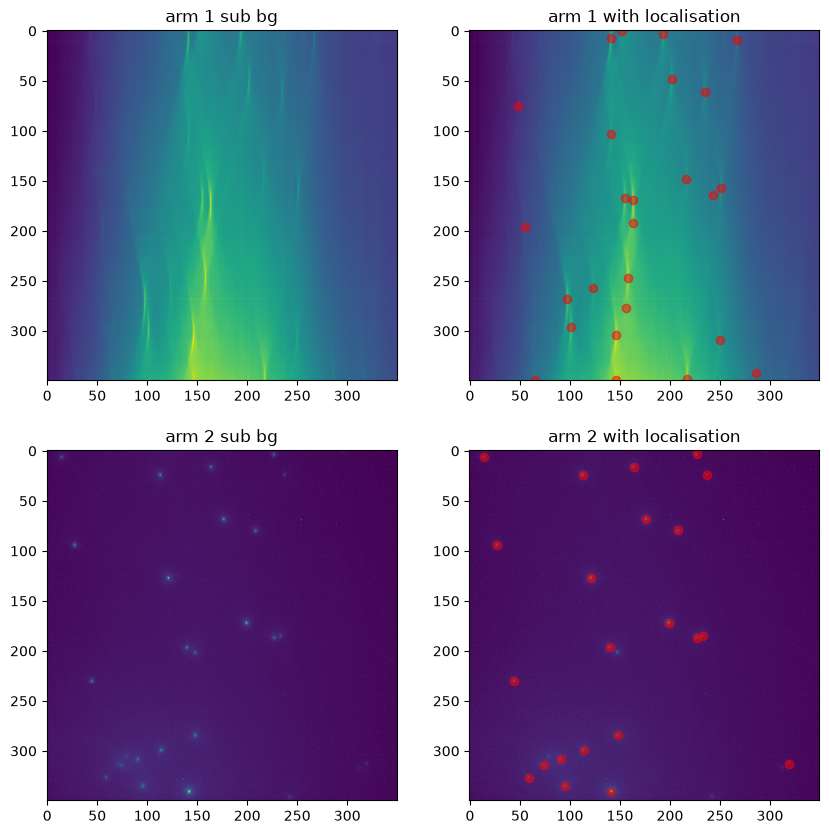

In [14]:
bead_locs_1 = remove_near_duplicates(np.array(arm_1_df), 20, 20, 20)
bead_locs_2 = remove_near_duplicates(np.array(arm_2_df), 45, 45, 45)

fig, ax = plt.subplots(2, 2, figsize=(10, 10))
ax[0, 0].set_title("arm 1 sub bg")
ax[0, 0].imshow(np.sum(normalised_arm_1, 0))
ax[0, 1].set_title("arm 1 with localisation")
ax[0, 1].imshow(np.sum(normalised_arm_1, 0))
ax[0, 1].scatter(bead_locs_1[:, 2], bead_locs_1[:, 1], alpha=0.5, color="red")
ax[1, 0].set_title("arm 2 sub bg")
ax[1, 0].imshow(np.sum(normalised_arm_2, 0))
ax[1, 1].set_title("arm 2 with localisation")
ax[1, 1].imshow(np.sum(normalised_arm_2, 0))
ax[1, 1].scatter(bead_locs_2[:, 2], bead_locs_2[:, 1], alpha=0.5, color="red")


# Generate Correspondence Pairs

get_descriptors() calculates all possible tetrahedral (4 point) descriptors between the points that have been localised in the above cell.

This method is controlled by the hyperparameter threshold, which limits the size of the descriptor by only generating tetrahedra with a combined side length smaller than the threshold. 

In [15]:
descriptors_1, side_lengths_1 = get_descriptors(bead_locs_1, threshold=800)
descriptors_2, side_lengths_2 = get_descriptors(bead_locs_2, threshold=800)

Identifying descriptors: 100%|██████████| 7315/7315 [00:00<00:00, 109461.65it/s]


Comparison of descriptors from both volumes to pair closest matching descriptors. Mutual matching considered, ie if descriptor 1a's best match is descriptor 2c, then if and only if 2c's best match is also 1a are descriptors considered 'matching'.

Function also only considers matching descriptors at similar locations in their respective volumes, controlled by 'tolerance'.  See 

In [16]:
sorted_matches, sorted_lowest_differences = match_descriptors(
    descriptors_1, side_lengths_1, descriptors_2, side_lengths_2, tolerance=80
)

correspondence_pairs = get_correspondence_pairs(sorted_matches)

Matching descriptors - generating the difference matrix:   0%|          | 0/545 [00:00<?, ?it/s]

Matching descriptors - generating the difference matrix: 100%|██████████| 545/545 [00:00<00:00, 5843.01it/s]


Difference matrix dimensions:  (545, 75)
Number of mutual matches:  13


Identifying correspondence pairs: 100%|██████████| 13/13 [00:00<00:00, 1359.65it/s]


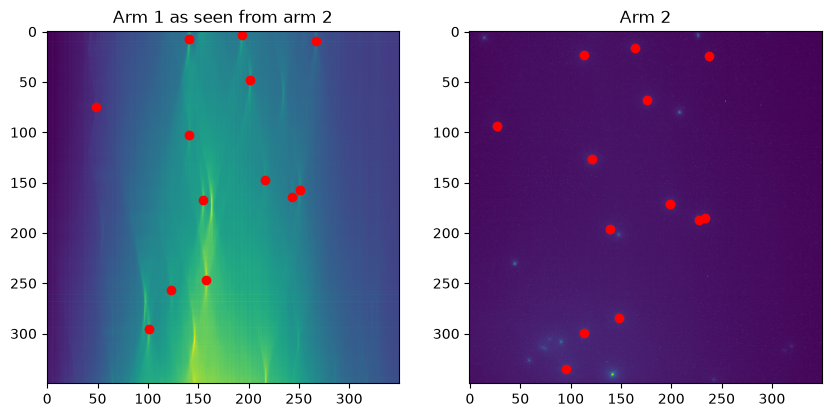

In [17]:
correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]

fig, ax = plt.subplots(1, 2, figsize = (10, 5))
ax[0].set_title("Arm 1 as seen from arm 2")
ax[0].imshow(np.sum(arm_1, 0))
ax[0].scatter(correspondence_pairs_1[:, 2], correspondence_pairs_1[:,1], color = 'red') #from above

ax[1].set_title("Arm 2")
ax[1].imshow(np.sum(arm_2, 0))
ax[1].scatter(correspondence_pairs_2[:, 2], correspondence_pairs_2[:,1], color = 'red')

Difference metric between quads 0.13799581160739294


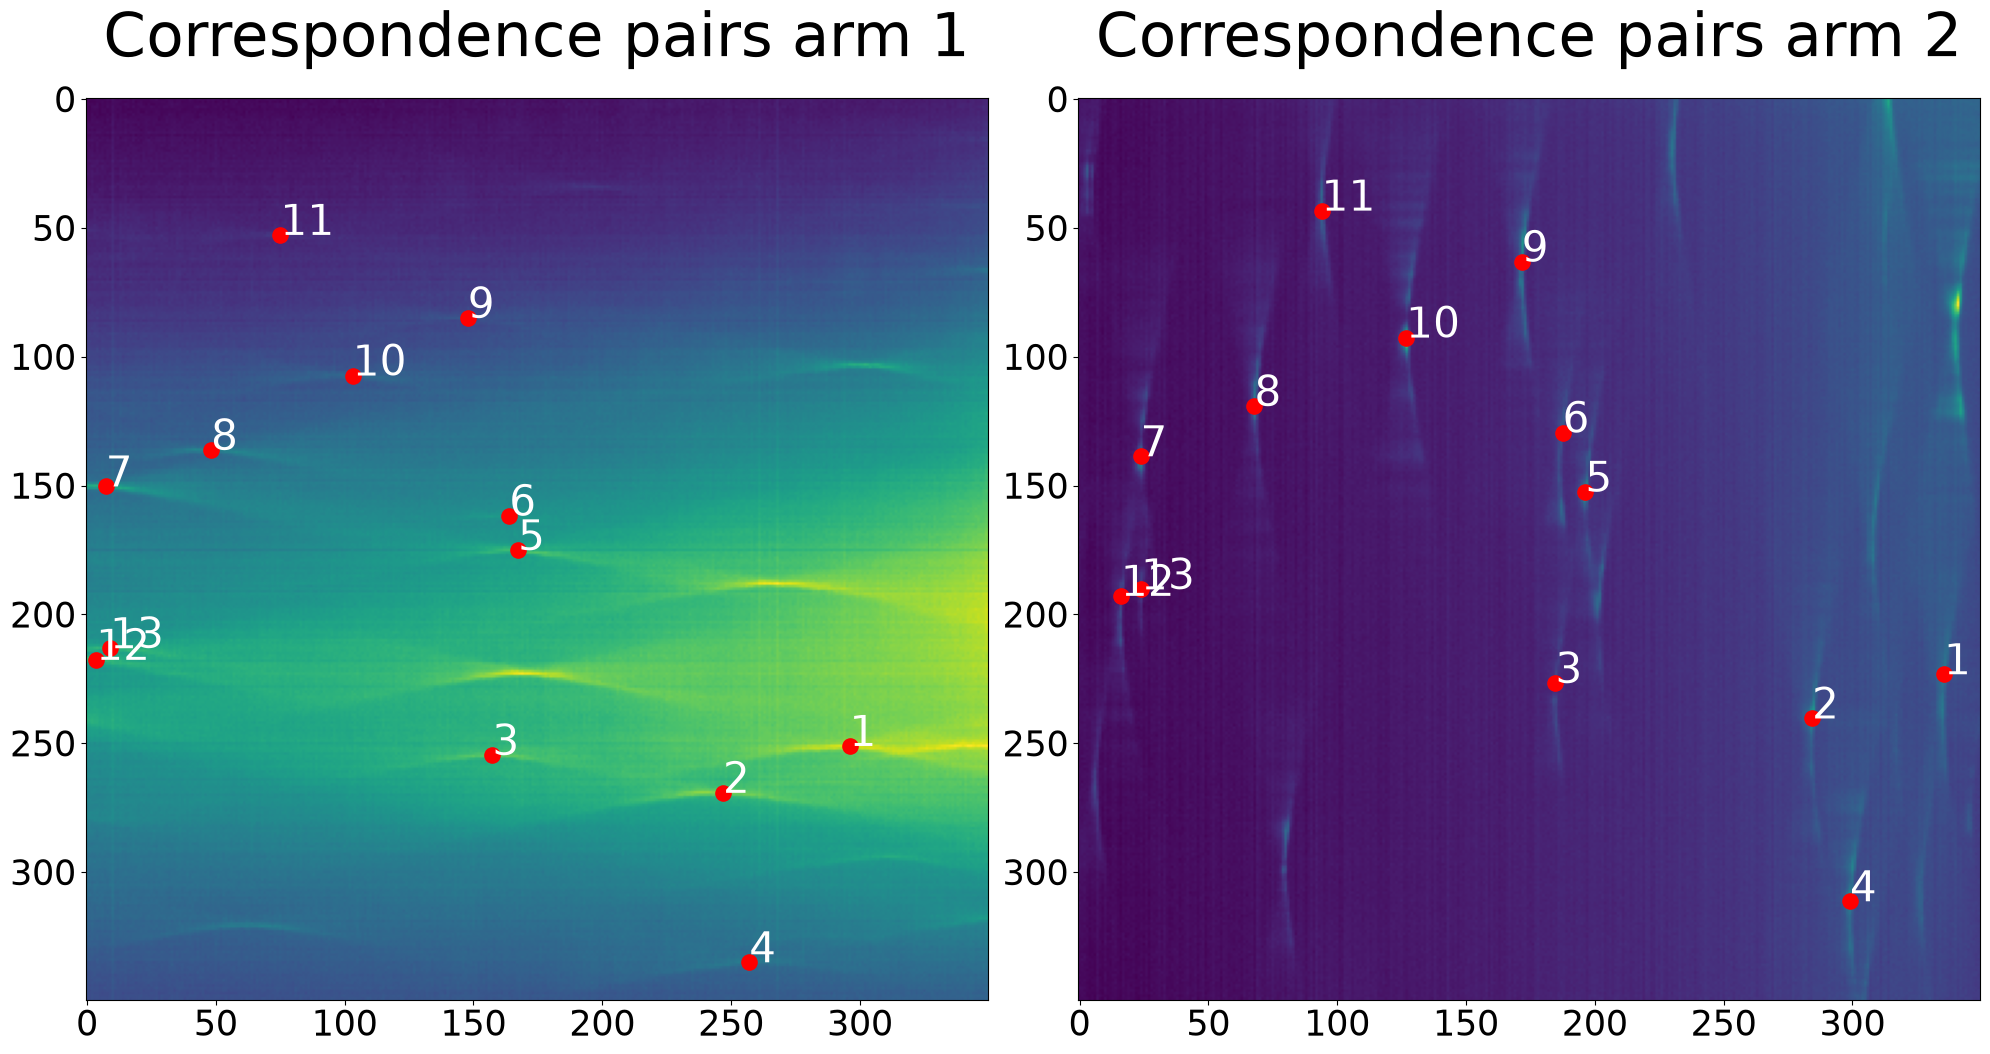

In [20]:
correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]

print("Difference metric between quads", sorted_lowest_differences[0])

figsize = (20, 20)
fig, ax = plt.subplots(1, 2, figsize=figsize)
ax[0].tick_params(axis="both", which="major", labelsize=25)
ax[1].tick_params(axis="both", which="major", labelsize=25)


ax[0].set_title("Correspondence pairs arm 1", fontsize=figsize[0] * 2.2, pad=30)
ax[0].imshow(np.sum(arm_1, 2))
ax[0].scatter(
    correspondence_pairs_1[:, 1],
    correspondence_pairs_1[:, 0],
    color="red",
    s=figsize[0] * 6,
)
ax[1].set_title("Correspondence pairs arm 2", fontsize=figsize[0] * 2.2, pad=30)
ax[1].imshow(np.sum(arm_2, 2))
ax[1].scatter(
    correspondence_pairs_2[:, 1],
    correspondence_pairs_2[:, 0],
    color="red",
    s=figsize[0] * 6,
)
plt.tight_layout()

for i, pair in enumerate(correspondence_pairs):
    ax[0].annotate(
        i + 1, (pair[0, 1], pair[0, 0]), color="white", fontsize=figsize[0] * 1.5
    )
    ax[1].annotate(
        i + 1, (pair[1, 1], pair[1, 0]), color="white", fontsize=figsize[0] * 1.5
    )

plt.savefig("../imgs/numbered_correspondence_pairs.svg", dpi=300)

[[251.07601495 295.95240028 101.23367225]
 [175.15320875 167.34583891 155.1067221 ]
 [269.26633406 246.8359426  158.18481892]
 [335.03460709 257.01945254 123.25703228]]
[[152.45403132 196.37033403 139.59267396]
 [311.35221916 299.02639427 113.71532197]
 [240.40104269 284.32832759 147.67240442]
 [223.23889417 335.5420666   95.08565377]]
Difference metric between quads 0.13799581160739294


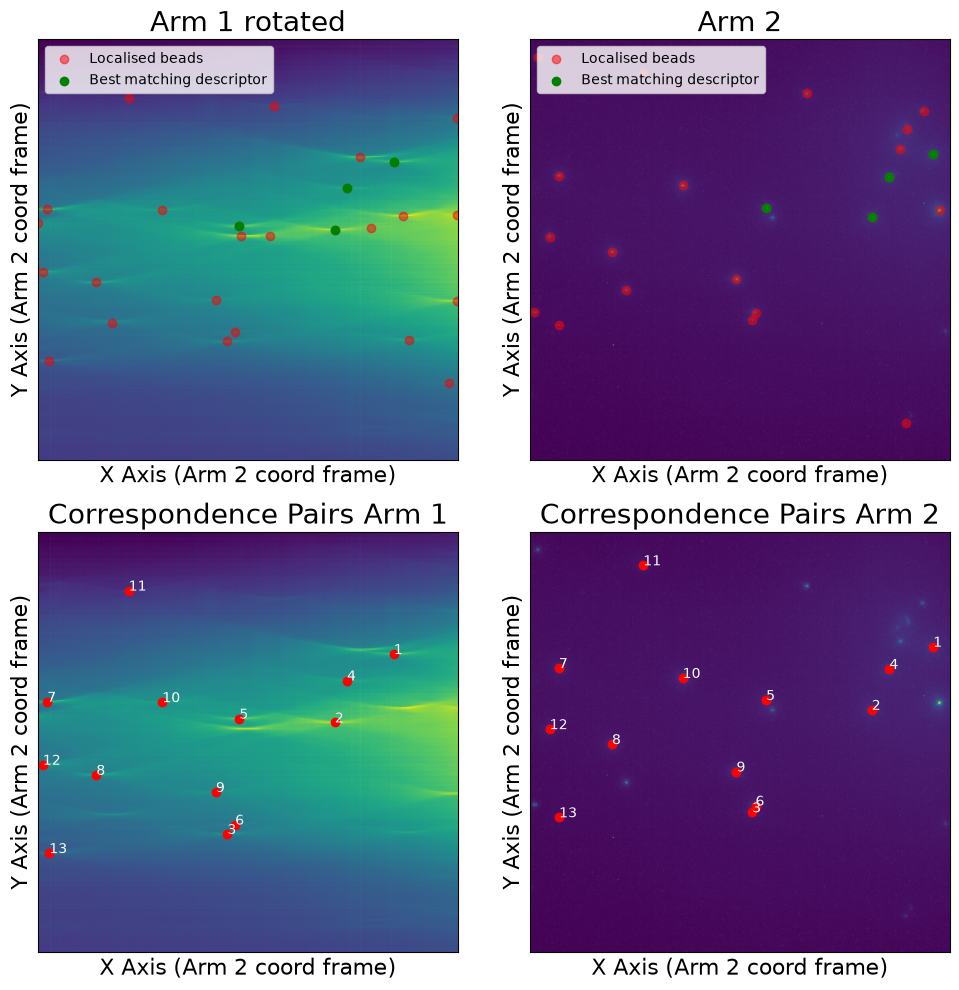

In [22]:
correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]

quad_1 = sorted_matches[1, 0, :, :]
quad_2 = sorted_matches[1, 1, :, :]
print(quad_1)

print(quad_2)
print('Difference metric between quads', sorted_lowest_differences[0])


fig, ax = plt.subplots(2, 2, figsize=(10, 10))
plt.setp(ax, xticks=[], yticks=[])
ax[0, 0].set_title("Arm 1 rotated", fontsize = 20)
ax[0, 0].imshow(np.swapaxes(np.sum(arm_1, 0), 0, 1))
ax[0, 0].scatter(bead_locs_1[:,1], bead_locs_1[:, 2], alpha=0.5, color="red", label = "Localised beads")
ax[0, 0].scatter(quad_1[:, 1], quad_1[:, 2], color = 'green', label="Best matching descriptor")
ax[0, 0].set_xlabel("X Axis (Arm 2 coord frame)", fontsize = 16)
ax[0, 0].set_ylabel("Y Axis (Arm 2 coord frame)", fontsize = 16)
ax[0, 0].legend(loc=2)
ax[0, 1].set_title("Arm 2", fontsize = 20)
ax[0, 1].imshow(np.swapaxes(np.sum(arm_2, 0), 0, 1))
ax[0, 1].scatter(bead_locs_2[:, 1], bead_locs_2[:, 2], alpha=0.5, color="red", label = "Localised beads")
ax[0, 1].scatter(quad_2[:, 1], quad_2[:, 2], color = 'green', label="Best matching descriptor")
ax[0, 1].set_xlabel("X Axis (Arm 2 coord frame)", fontsize = 16)
ax[0, 1].set_ylabel("Y Axis (Arm 2 coord frame)", fontsize = 16)
ax[0, 1].legend(loc=2)
ax[1, 0].set_title("Correspondence Pairs Arm 1", fontsize = 20)
ax[1, 0].imshow(np.swapaxes(np.sum(arm_1, 0), 0, 1))
ax[1, 0].scatter(
    correspondence_pairs_1[:, 1], correspondence_pairs_1[:, 2], color="red"
)
ax[1, 0].set_xlabel("X Axis (Arm 2 coord frame)", fontsize = 16)
ax[1, 0].set_ylabel("Y Axis (Arm 2 coord frame)", fontsize = 16)
ax[1, 1].set_title("Correspondence Pairs Arm 2", fontsize = 20)
ax[1, 1].imshow(np.swapaxes(np.sum(arm_2, 0), 0, 1))
ax[1, 1].scatter(
    correspondence_pairs_2[:, 1], correspondence_pairs_2[:, 2], color="red"
)
ax[1, 1].set_xlabel("X Axis (Arm 2 coord frame)", fontsize = 16)
ax[1, 1].set_ylabel("Y Axis (Arm 2 coord frame)", fontsize = 16)
plt.tight_layout()

for i, pair in enumerate(correspondence_pairs):
    ax[1, 0].annotate(i + 1, (pair[0, 1], pair[0, 2]), color = 'white')
    ax[1, 1].annotate(i + 1, (pair[1, 1], pair[1, 2]), color = 'white')

plt.savefig("../imgs/matched_correspondence_pairs.svg", dpi = 300)

# Calculate Transform w/ RANSAC 

In [23]:
print("Number of correspondence pairs found: ", (correspondence_pairs.shape)[0])

correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]
model, inliers = ransac(
    (correspondence_pairs_2[:], correspondence_pairs_1[:]),
    SimilarityTransform,
    min_samples=10,
    residual_threshold=10,
    max_trials=100000,
)
print("Number of inliers detected: ", np.array(inliers)[inliers == True].shape)

# Generated is a point array in lab z, y, x coordinates (same reference frame as ref)
print(bead_locs_2.shape)
intermediate = model(bead_locs_2)
intermediate_correspondence = model(correspondence_pairs_1[:])
generated = intermediate[:, [2, 1, 0]]

matched_pairs = intermediate_correspondence[:, [2, 1, 0]]
print("Calculated transform: ", model)

Number of correspondence pairs found:  13
Number of inliers detected:  (11,)
(22, 3)
Calculated transform:  <SimilarityTransform(matrix=
    [[ 9.72216931e-01,  5.50212161e-02,  2.98741719e-02,  1.32199985e+01],
     [-5.68468655e-02,  9.70563150e-01,  6.24593139e-02, -2.24600522e+01],
     [-2.62342190e-02, -6.40733782e-02,  9.71767425e-01,  3.80559059e+01],
     [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])>


# Plot Projections

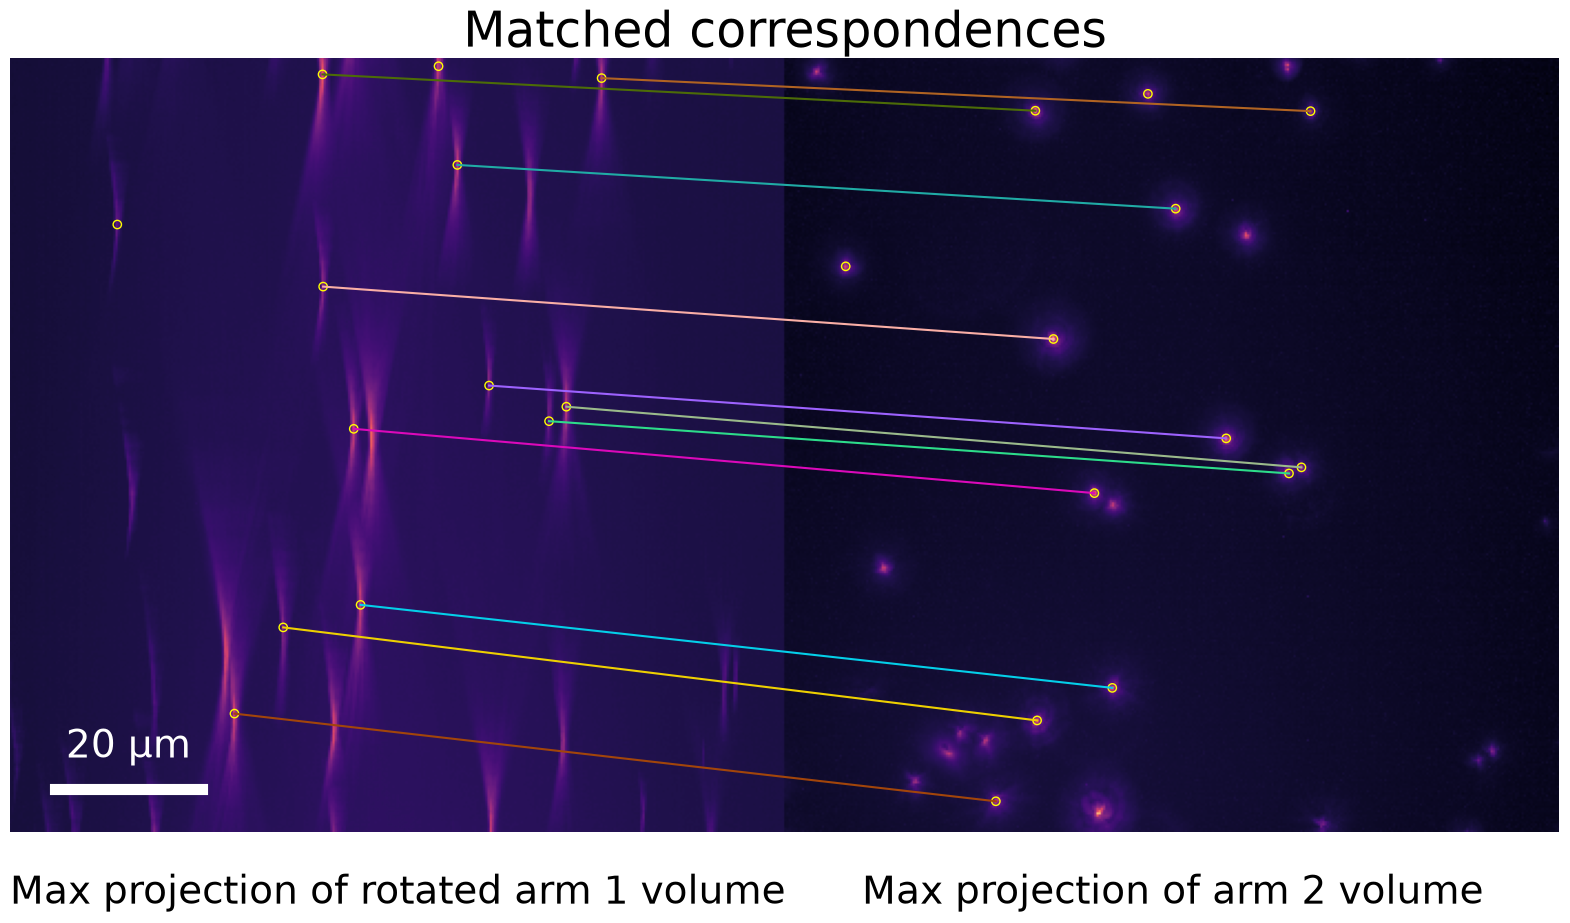

In [25]:
keypoints0 = np.array(
    list(zip(correspondence_pairs_1[:, 1], correspondence_pairs_1[:, 2]))
)
keypoints1 = np.array(
    list(zip(correspondence_pairs_2[:, 1], correspondence_pairs_2[:, 2]))
)

inlier_idxs = np.nonzero(inliers)[0]

arm_1_mp = np.max(arm_1, 0)
arm_2_mp = np.max(arm_2, 0)
# scalebar parameters
pixel_size_um = 0.3   # set this to your actual voxel size
bar_length_um = 20
bar_length_px = bar_length_um / pixel_size_um

fig, ax = plt.subplots(figsize=(20, 20))
plot_matched_features(
    image0=arm_1_mp,
    image1=arm_2_mp,
    # Keypoints in row col order - y x
    keypoints0=keypoints0,
    keypoints1=keypoints1,
    keypoints_color="yellow",
    matches=np.column_stack((inlier_idxs, inlier_idxs)),
    ax=ax,
)

ax.axis("off")
ax.set_title("Matched correspondences", fontsize=35)

for im in ax.get_images():
    im.set_cmap("magma")
    im.set_norm(PowerNorm(gamma=0.4))

h0, w0 = arm_1_mp.shape[:2]

ax.text(
    w0 / 2,
    h0 + 36,
    "Max projection of rotated arm 1 volume",
    ha="center",
    va="bottom",
    fontsize=28,
)
ax.text(
    w0 + arm_2_mp.shape[1] / 2,
    h0 + 36,
    "Max projection of arm 2 volume",
    ha="center",
    va="bottom",
    fontsize=28,
)

# --- scalebar, bottom left corner ---
x_start = 20
y_pos = h0 - 20
ax.plot([x_start, x_start + bar_length_px], [y_pos, y_pos], color='white', linewidth=8)
ax.text(
    x_start + bar_length_px / 2,
    y_pos - 10,
    f'{bar_length_um} µm',
    color='white',
    ha='center',
    va='bottom',
    fontsize=28,
)

plt.savefig("../imgs/correspondence_matching_w_lines.svg", dpi=300)
plt.show()

# Optional - Calculate Avg Transform
This was not implemented in the final results but was tested briefly during the internship. It has not been testedt in a while, and may be incorrect.

### Calculate average of affine transforms

Element wise averaging of affine transformations typically does not work. The average of the translational part can be done this way, but averaging rotation matrices is not as trivial. Rotation matrices must conform to the following properties: 

$R^T = R^{-1}$ : Rotation matrices are orthogonal.

And,

$det R = \pm 1$

Averaging a rotation matrix can break these properties, resulting in very different transforms.

A way to solve this, is to calculate the element-wise average and project the result onto the nearest valid rotation matrix. 

The mean of numbers is the value that minimises the dispersion, defined as:

$disp = \sum_{i=0}^{\inf} (x_i - mean)^2$

For rotations, a similar definition of dispersion is used, with a mean rotation matrix $Q$ that minimises the dispersion result:

$disp = \sum_{i=0}^{\inf} Tr( (R_i - Q)^T (R_i - Q))$

Where Tr denotes the Trace of the matrix.

$Q$ can be computed practically using SVD:

Mean matrix (elementwise) of rotations:

$M = \frac{\sum^{i} R_i}{N}$ where $N$ is the number of rotation matrices.

Taking the SVD of above:

$M = U D V^T$ (look into how this is calculated)

The closest rotation matrix $Q$ to $M$ can be calculated as:

$Q = U V^T$


In [ ]:
def average_affine(affine_transform_array):
    num_affine_matrices = affine_transform_array.shape[0]
    translation_total = np.zeros(3).T
    rotation_total = np.zeros((3, 3))
    for transform in affine_transform_array:
        translation = transform[:-1, -1]
        translation_total += translation

        rotation = transform[:-1, :3]
        rotation_total += rotation

    translation_avg = translation_total / num_affine_matrices
    M = rotation_total / num_affine_matrices

    U, D, V_transpose = svd(M)

    Q = U @ V_transpose

    affine_avg = np.eye(4)
    affine_avg[0:3, 0:3] = Q
    affine_avg[:-1, 3] = translation_avg

    return affine_avg


affine_transforms = np.array([affine_1, affine_2])


avg_affine = average_affine(affine_transforms)
print("Average affine transform = ", avg_affine)
print("Affine transform 1 = ", affine_1)
print("Affine transform 2 = ", affine_2)

NameError: name 'affine_1' is not defined